**Part one regression:**


1. Applying the Exploratory data analysis technics to understand and visualize the given Dataset.

In [2]:
#Loadig and taking a first look
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('prices-split-adjusted.csv')

print(df.head())      # taking a look at the first rows


         date symbol        open       close         low        high  \
0  2016-01-05   WLTW  123.430000  125.839996  122.309998  126.250000   
1  2016-01-06   WLTW  125.239998  119.980003  119.940002  125.540001   
2  2016-01-07   WLTW  116.379997  114.949997  114.930000  119.739998   
3  2016-01-08   WLTW  115.480003  116.620003  113.500000  117.440002   
4  2016-01-11   WLTW  117.010002  114.970001  114.089996  117.330002   

      volume  
0  2163600.0  
1  2386400.0  
2  2489500.0  
3  2006300.0  
4  1408600.0  


In [3]:
print(df.shape)       # here rows and columns


(851264, 7)


In [4]:
print(df.info())      # getting more infos about it and columns types and non null columns count  + dtype

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    851264 non-null  object 
 1   symbol  851264 non-null  object 
 2   open    851264 non-null  float64
 3   close   851264 non-null  float64
 4   low     851264 non-null  float64
 5   high    851264 non-null  float64
 6   volume  851264 non-null  float64
dtypes: float64(5), object(2)
memory usage: 45.5+ MB
None


In [8]:
#Converting  the date column cz it must be a real datetime object so we can sort or plot it ...

df['date'] = pd.to_datetime(df['date'])
print(df['date'].min(), df['date'].max())
print("Number of stocks:", df['symbol'].nunique())

2010-01-04 00:00:00 2016-12-30 00:00:00
Number of stocks: 501


In [7]:
# some statistics more as a description for the dataset
print(df.describe())

# noticing the volume values are a bit weird , prices go from 1 to 1600 while the volume values are from 0 to 8.596434e+08 which signals --> OUTLIERS!!
# so we need to scale it so the volume does not dominate and lead to unstable training

                                date           open          close  \
count                         851264  851264.000000  851264.000000   
mean   2013-07-21 02:56:29.294037760      64.993618      65.011913   
min              2010-01-04 00:00:00       1.660000       1.590000   
25%              2011-10-19 00:00:00      31.270000      31.292776   
50%              2013-08-02 00:00:00      48.459999      48.480000   
75%              2015-04-24 00:00:00      75.120003      75.139999   
max              2016-12-30 00:00:00    1584.439941    1578.130005   
std                              NaN      75.203893      75.201216   

                 low           high        volume  
count  851264.000000  851264.000000  8.512640e+05  
mean       64.336541      65.639748  5.415113e+06  
min         1.500000       1.810000  0.000000e+00  
25%        30.940001      31.620001  1.221500e+06  
50%        47.970001      48.959999  2.476250e+06  
75%        74.400002      75.849998  5.222500e+06  
max  

In [9]:
# looking for missing or duplicates
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

date      0
symbol    0
open      0
close     0
low       0
high      0
volume    0
dtype: int64
Duplicates: 0


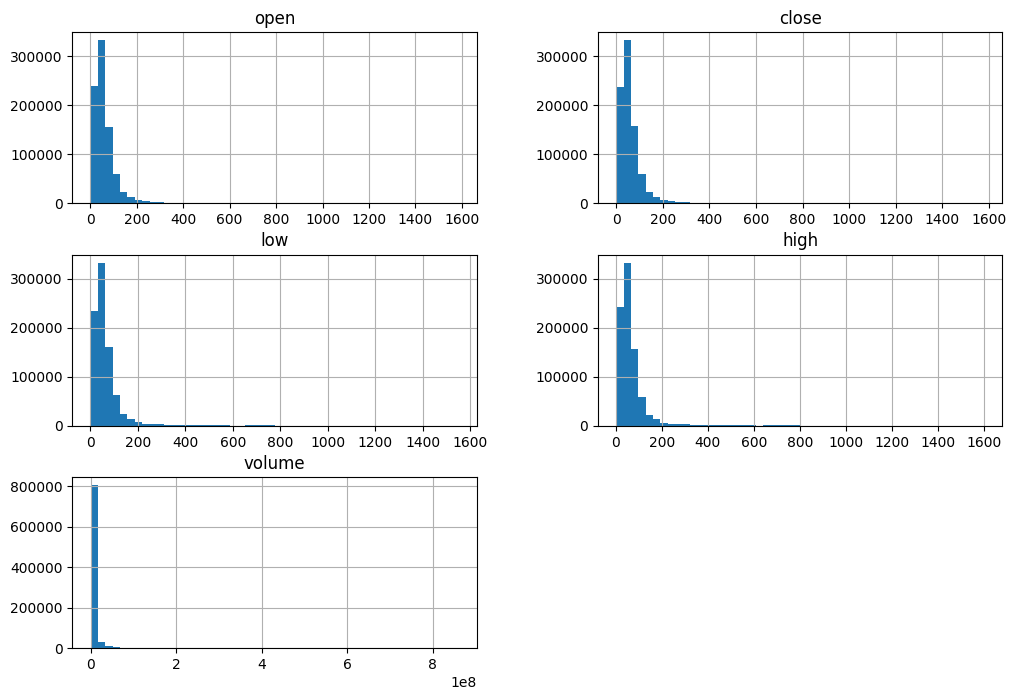

In [10]:
#the distribution
df[['open', 'close', 'low', 'high', 'volume']].hist(bins=50, figsize=(12, 8))
plt.show()

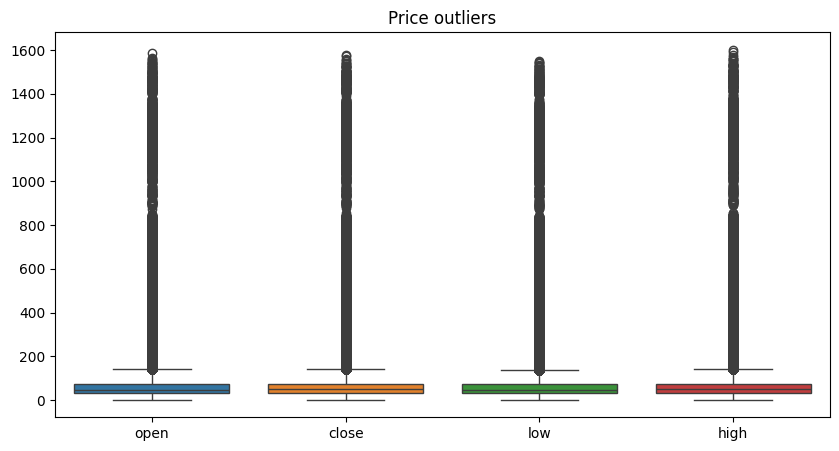

In [11]:
# ploting outliers by using boxplot
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[['open', 'close', 'low', 'high']])
plt.title('Price outliers')
plt.show()

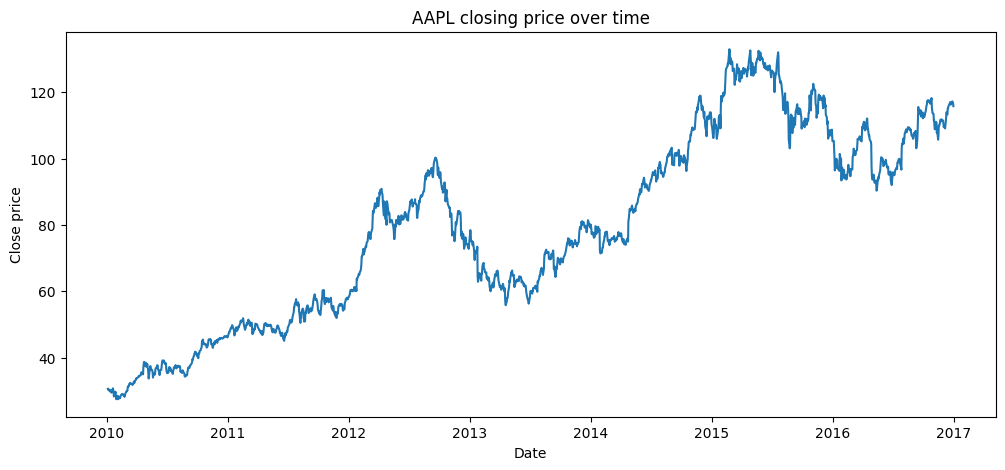

In [12]:
# here ploting apple's stock to understand how it behaves over time ( ups /downs )
stock = df[df['symbol'] == 'AAPL'].sort_values('date')

plt.figure(figsize=(12, 5))
plt.plot(stock['date'], stock['close'])
plt.title('AAPL closing price over time')
plt.xlabel('Date')
plt.ylabel('Close price')
plt.show()

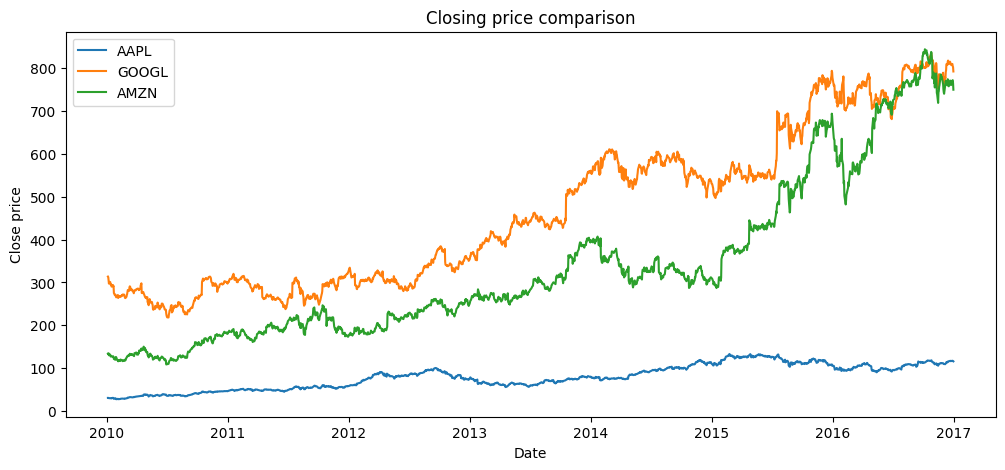

In [13]:
# a comparaison between apple, amazon and google
plt.figure(figsize=(12, 5))
for sym in ['AAPL', 'GOOGL', 'AMZN']:
    s = df[df['symbol'] == sym].sort_values('date')
    plt.plot(s['date'], s['close'], label=sym)
plt.legend()
plt.title('Closing price comparison')
plt.xlabel('Date')
plt.ylabel('Close price')
plt.show()

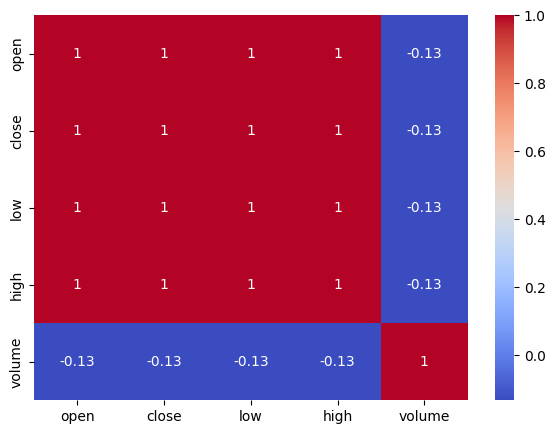

In [14]:
#correlation
#shows how values move together
plt.figure(figsize=(7, 5))
sns.heatmap(df[['open','close','low','high','volume']].corr(),
            annot=True, cmap='coolwarm')
plt.show()
#here low , close, high ,open are strongly correlated while volume is not !

** 2 . Building a Deep Neural Network in PyTorch for Regression**

In [15]:
# creating target to define what r we going to predict which is tomorrow's price based on today's low,high,close,open!df = df.sort_values(['symbol', 'date'])
df['target'] = df.groupby('symbol')['close'].shift(-1)
df = df.dropna()

In [16]:
#splitting data by time
dates = np.sort(df['date'].unique())
d1 = dates[int(len(dates) * 0.70)]
d2 = dates[int(len(dates) * 0.85)]

train = df[df['date'] < d1]
val   = df[(df['date'] >= d1) & (df['date'] < d2)]
test  = df[df['date'] >= d2]

In [17]:
#scaling features cz as we said earlier the volume has bigger values !!
from sklearn.preprocessing import StandardScaler

cols = ['open', 'high', 'low', 'close', 'volume']
scaler = StandardScaler()

X_train = scaler.fit_transform(train[cols])   # learn mean/std from train ONLY
X_val   = scaler.transform(val[cols])
X_test  = scaler.transform(test[cols])

In [23]:
#tensors and dataloarders
import torch
from torch.utils.data import TensorDataset, DataLoader
# Validation tensors
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(val['target'].values, dtype=torch.float32).reshape(-1, 1)

# Test tensors (needed later for evaluation)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(test['target'].values, dtype=torch.float32).reshape(-1, 1)
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t),
                          batch_size=256, shuffle=True)

In [20]:
#defining the model
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self, in_features=5, h1=64, h2=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, h1), #5 inputs feed 64 neurons
            nn.ReLU(),                  #activation
            nn.Linear(h1, h2),
            nn.ReLU(),
            nn.Linear(h2, 1)
        )

    def forward(self, x):
        return self.net(x)

In [21]:
#loss and optimizer
model = MLP()
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [24]:
#training loop
for epoch in range(20):
    model.train()
    for xb, yb in train_loader:
        pred = model(xb)
        loss = loss_fn(pred, yb)

        optimizer.zero_grad()   # clear old gradients
        loss.backward()         # compute gradients
        optimizer.step()        # update weights

    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(X_val_t), y_val_t).item()
    print(epoch + 1, val_loss)

1 5.098546981811523
2 5.731870651245117
3 4.92350959777832
4 5.055261135101318
5 5.132723808288574
6 7.563713550567627
7 5.2649126052856445
8 4.785770416259766
9 5.243948459625244
10 4.902891635894775
11 4.575143337249756
12 6.048380374908447
13 5.212237358093262
14 5.155783653259277
15 4.813989639282227
16 4.7934136390686035
17 5.3329386711120605
18 5.100490093231201
19 4.4829888343811035
20 4.635473728179932


In [25]:
#evaluate on test
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

model.eval()
with torch.no_grad():
    pred = model(X_test_t).numpy().ravel()
actual = y_test_t.numpy().ravel()

print("MAE :", mean_absolute_error(actual, pred))
print("RMSE:", np.sqrt(mean_squared_error(actual, pred)))
print("R2  :", r2_score(actual, pred))

MAE : 1.0186642408370972
RMSE: 2.2012254899678783
R2  : 0.9995453357696533


**3.Hyperparameter tuning with GridSearchCV + skorch**

In [27]:
#Redefining the model with tunable sizes
#The sizes must be constructor arguments so the grid can change them
import torch
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self, in_features=5, h1=64, h2=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, h1),
            nn.ReLU(),
            nn.Linear(h1, h2),
            nn.ReLU(),
            nn.Linear(h2, 1)
        )

    def forward(self, x):
        return self.net(x)

In [28]:
#Preparing a subsample for the search for tunni only
import numpy as np

rng = np.random.default_rng(42)

idx_tr = rng.choice(len(X_train), 100_000, replace=False)
idx_va = rng.choice(len(X_val),   30_000,  replace=False)

X_gs = np.vstack([X_train[idx_tr], X_val[idx_va]]).astype(np.float32)
y_gs = np.concatenate([train['target'].values[idx_tr],
                       val['target'].values[idx_va]]).astype(np.float32).reshape(-1, 1)

In [29]:
#gridsearch uses k fold which would break the time logic we need !!

from sklearn.model_selection import PredefinedSplit

# -1 = always in training, 0 = validation fold
test_fold = np.concatenate([-np.ones(len(idx_tr)), np.zeros(len(idx_va))])
cv = PredefinedSplit(test_fold)

In [31]:
!pip install skorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 271.6/271.6 kB 5.9 MB/s eta 0:00:00


In [32]:
#wrapping
from skorch import NeuralNetRegressor

net = NeuralNetRegressor(
    module=MLP,
    criterion=nn.MSELoss,
    optimizer=torch.optim.Adam,
    batch_size=256,
    train_split=None,   # we use GridSearchCV's split instead of skorch's own
    verbose=0,
    device='cpu',
)

In [33]:
#defining the grid
param_grid = {
    'lr':         [0.001, 0.01], #learning rate
    'optimizer':  [torch.optim.Adam, torch.optim.SGD],
    'max_epochs': [10, 20],
    'module__h1': [32, 64, 128],
    'module__h2': [16, 32],
}

In [34]:
#running the search
from sklearn.model_selection import GridSearchCV

gs = GridSearchCV(
    net,
    param_grid,
    cv=cv,
    scoring='neg_mean_absolute_error',
    refit=True,
    verbose=2,
)

gs.fit(X_gs, y_gs)

print("Best score (neg MAE):", gs.best_score_)
print("Best params:", gs.best_params_)

Fitting 1 folds for each of 48 candidates, totalling 48 fits
[CV] END lr=0.001, max_epochs=10, module__h1=32, module__h2=16, optimizer=<class 'torch.optim.adam.Adam'>; total time=  22.5s
[CV] END lr=0.001, max_epochs=10, module__h1=32, module__h2=16, optimizer=<class 'torch.optim.sgd.SGD'>; total time=  13.1s
[CV] END lr=0.001, max_epochs=10, module__h1=32, module__h2=32, optimizer=<class 'torch.optim.adam.Adam'>; total time=  14.6s
[CV] END lr=0.001, max_epochs=10, module__h1=32, module__h2=32, optimizer=<class 'torch.optim.sgd.SGD'>; total time=  13.4s
[CV] END lr=0.001, max_epochs=10, module__h1=64, module__h2=16, optimizer=<class 'torch.optim.adam.Adam'>; total time=  14.4s
[CV] END lr=0.001, max_epochs=10, module__h1=64, module__h2=16, optimizer=<class 'torch.optim.sgd.SGD'>; total time=  13.4s
[CV] END lr=0.001, max_epochs=10, module__h1=64, module__h2=32, optimizer=<class 'torch.optim.adam.Adam'>; total time=  17.1s
[CV] END lr=0.001, max_epochs=10, module__h1=64, module__h2=32,

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:960: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 949, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 288, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 388, in _score
    return self._sign * self._score_func(y_true, y_pred, **scoring_kwargs)
                        ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/utils/_param_valid

[CV] END lr=0.01, max_epochs=10, module__h1=32, module__h2=16, optimizer=<class 'torch.optim.sgd.SGD'>; total time=  12.4s
[CV] END lr=0.01, max_epochs=10, module__h1=32, module__h2=32, optimizer=<class 'torch.optim.adam.Adam'>; total time=  14.5s


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:960: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 949, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 288, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 388, in _score
    return self._sign * self._score_func(y_true, y_pred, **scoring_kwargs)
                        ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/utils/_param_valid

[CV] END lr=0.01, max_epochs=10, module__h1=32, module__h2=32, optimizer=<class 'torch.optim.sgd.SGD'>; total time=  13.6s
[CV] END lr=0.01, max_epochs=10, module__h1=64, module__h2=16, optimizer=<class 'torch.optim.adam.Adam'>; total time=  14.9s
[CV] END lr=0.01, max_epochs=10, module__h1=64, module__h2=16, optimizer=<class 'torch.optim.sgd.SGD'>; total time=  13.1s
[CV] END lr=0.01, max_epochs=10, module__h1=64, module__h2=32, optimizer=<class 'torch.optim.adam.Adam'>; total time=  14.9s


...

[CV] END lr=0.01, max_epochs=20, module__h1=64, module__h2=32, optimizer=<class 'torch.optim.sgd.SGD'>; total time=  26.0s
[CV] END lr=0.01, max_epochs=20, module__h1=128, module__h2=16, optimizer=<class 'torch.optim.adam.Adam'>; total time=  30.0s


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:960: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 949, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 288, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 388, in _score
    return self._sign * self._score_func(y_true, y_pred, **scoring_kwargs)
                        ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/utils/_param_valid

[CV] END lr=0.01, max_epochs=20, module__h1=128, module__h2=16, optimizer=<class 'torch.optim.sgd.SGD'>; total time=  26.7s
[CV] END lr=0.01, max_epochs=20, module__h1=128, module__h2=32, optimizer=<class 'torch.optim.adam.Adam'>; total time=  30.5s


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:960: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 949, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 288, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 388, in _score
    return self._sign * self._score_func(y_true, y_pred, **scoring_kwargs)
                        ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/utils/_param_valid

[CV] END lr=0.01, max_epochs=20, module__h1=128, module__h2=32, optimizer=<class 'torch.optim.sgd.SGD'>; total time=  26.7s
Best score (neg MAE): -1.0572633743286133
Best params: {'lr': 0.001, 'max_epochs': 20, 'module__h1': 128, 'module__h2': 32, 'optimizer': <class 'torch.optim.adam.Adam'>}


In [35]:
import pandas as pd
results = pd.DataFrame(gs.cv_results_)
print(results[['params', 'mean_test_score']]
      .sort_values('mean_test_score', ascending=False)
      .head(10))

                                               params  mean_test_score
22  {'lr': 0.001, 'max_epochs': 20, 'module__h1': ...        -1.057263
20  {'lr': 0.001, 'max_epochs': 20, 'module__h1': ...        -1.101759
14  {'lr': 0.001, 'max_epochs': 20, 'module__h1': ...        -1.103915
2   {'lr': 0.001, 'max_epochs': 10, 'module__h1': ...        -1.104807
18  {'lr': 0.001, 'max_epochs': 20, 'module__h1': ...        -1.120474
4   {'lr': 0.001, 'max_epochs': 10, 'module__h1': ...        -1.123618
0   {'lr': 0.001, 'max_epochs': 10, 'module__h1': ...        -1.124775
36  {'lr': 0.01, 'max_epochs': 20, 'module__h1': 3...        -1.131876
12  {'lr': 0.001, 'max_epochs': 20, 'module__h1': ...        -1.138068
16  {'lr': 0.001, 'max_epochs': 20, 'module__h1': ...        -1.142391


In [36]:
best = gs.best_params_
model = MLP(h1=best['module__h1'], h2=best['module__h2'])
optimizer = best['optimizer'](model.parameters(), lr=best['lr'])
epochs = best['max_epochs']

**4. Loss/Epochs and Accuracy/Epochs plots**

In [37]:
import torch, torch.nn as nn, numpy as np
from torch.utils.data import TensorDataset, DataLoader

def r2(pred, y):
    ss_res = ((y - pred) ** 2).sum()
    ss_tot = ((y - y.mean()) ** 2).sum()
    return (1 - ss_res / ss_tot).item()

def train_model(model, optimizer, epochs=20, batch_size=256):
    loss_fn = nn.MSELoss()
    loader = DataLoader(TensorDataset(X_train_t, y_train_t),
                        batch_size=batch_size, shuffle=True)
    hist = {'train_loss': [], 'test_loss': [],
            'train_mae': [], 'test_mae': [],
            'train_r2': [], 'test_r2': []}

    for epoch in range(epochs):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()

        # evaluate on full train and test after each epoch
        model.eval()
        with torch.no_grad():
            ptr, pte = model(X_train_t), model(X_test_t)
            hist['train_loss'].append(loss_fn(ptr, y_train_t).item())
            hist['test_loss'].append(loss_fn(pte, y_test_t).item())
            hist['train_mae'].append((ptr - y_train_t).abs().mean().item())
            hist['test_mae'].append((pte - y_test_t).abs().mean().item())
            hist['train_r2'].append(r2(ptr, y_train_t))
            hist['test_r2'].append(r2(pte, y_test_t))
        print(f"Epoch {epoch+1:2d} | train MAE {hist['train_mae'][-1]:.3f} "
              f"| test MAE {hist['test_mae'][-1]:.3f}")
    return hist

model = MLP(h1=128, h2=32)
opt = torch.optim.Adam(model.parameters(), lr=0.001)
hist_base = train_model(model, opt, epochs=20)

Epoch  1 | train MAE 0.765 | test MAE 1.116
Epoch  2 | train MAE 0.720 | test MAE 1.051
Epoch  3 | train MAE 0.743 | test MAE 1.049
Epoch  4 | train MAE 0.764 | test MAE 1.094
Epoch  5 | train MAE 0.771 | test MAE 1.125
Epoch  6 | train MAE 1.220 | test MAE 1.772
Epoch  7 | train MAE 0.875 | test MAE 1.347
Epoch  8 | train MAE 0.681 | test MAE 0.992
Epoch  9 | train MAE 0.678 | test MAE 0.997
Epoch 10 | train MAE 0.691 | test MAE 1.003
Epoch 11 | train MAE 0.714 | test MAE 1.012
Epoch 12 | train MAE 0.677 | test MAE 1.007
Epoch 13 | train MAE 0.686 | test MAE 0.985
Epoch 14 | train MAE 0.879 | test MAE 1.190
Epoch 15 | train MAE 0.702 | test MAE 0.992
Epoch 16 | train MAE 0.774 | test MAE 1.087
Epoch 17 | train MAE 0.698 | test MAE 1.034
Epoch 18 | train MAE 0.687 | test MAE 0.989
Epoch 19 | train MAE 0.675 | test MAE 0.995
Epoch 20 | train MAE 0.737 | test MAE 1.113


In [39]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Naive prediction: tomorrow's close = today's close
naive_pred = test['close'].values
actual = test['target'].values

print("Naive MAE :", mean_absolute_error(actual, naive_pred))
print("Naive RMSE:", np.sqrt(mean_squared_error(actual, naive_pred)))
print("Naive R2  :", r2_score(actual, naive_pred))

Naive MAE : 0.9502286613500485
Naive RMSE: 2.1349876199647784
Naive R2  : 0.9995722691599787


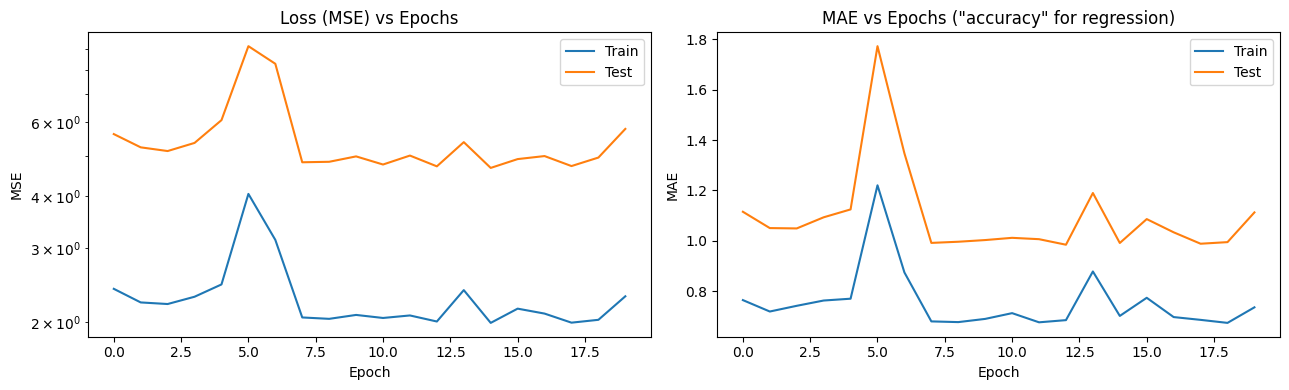

In [40]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(hist_base['train_loss'], label='Train')
ax[0].plot(hist_base['test_loss'], label='Test')
ax[0].set_title('Loss (MSE) vs Epochs')
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('MSE'); ax[0].legend()
ax[0].set_yscale('log')   # helpful: MSE drops by orders of magnitude

ax[1].plot(hist_base['train_mae'], label='Train')
ax[1].plot(hist_base['test_mae'], label='Test')
ax[1].set_title('MAE vs Epochs ("accuracy" for regression)')
ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('MAE'); ax[1].legend()

plt.tight_layout(); plt.show()

**5.Regularization and comparison**

In [41]:
#dropout
import torch, torch.nn as nn

class MLP_Reg(nn.Module):
    def __init__(self, in_features=5, h1=128, h2=32, p=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, h1), nn.ReLU(), nn.Dropout(p),
            nn.Linear(h1, h2),          nn.ReLU(), nn.Dropout(p),
            nn.Linear(h2, 1)
        )
    def forward(self, x):
        return self.net(x)

In [42]:
#early stopping and scheduler
import copy
from torch.utils.data import TensorDataset, DataLoader

def train_reg(model, optimizer, epochs=30, batch_size=256,
              patience=5, use_scheduler=True):
    loss_fn = nn.MSELoss()
    loader = DataLoader(TensorDataset(X_train_t, y_train_t),
                        batch_size=batch_size, shuffle=True)
    scheduler = (torch.optim.lr_scheduler.ReduceLROnPlateau(
                    optimizer, factor=0.5, patience=2)
                 if use_scheduler else None)

    hist = {'train_loss': [], 'test_loss': [], 'train_mae': [], 'test_mae': []}
    best_val, best_state, wait = float('inf'), None, 0

    for epoch in range(epochs):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad()
            loss_fn(model(xb), yb).backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            ptr, pva, pte = model(X_train_t), model(X_val_t), model(X_test_t)
            val_loss = loss_fn(pva, y_val_t).item()
            hist['train_loss'].append(loss_fn(ptr, y_train_t).item())
            hist['test_loss'].append(loss_fn(pte, y_test_t).item())
            hist['train_mae'].append((ptr - y_train_t).abs().mean().item())
            hist['test_mae'].append((pte - y_test_t).abs().mean().item())

        if scheduler: scheduler.step(val_loss)

        # early stopping decided on VALIDATION, never on test
        if val_loss < best_val:
            best_val, wait = val_loss, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience:
                print(f"Early stop at epoch {epoch+1}")
                break

    model.load_state_dict(best_state)   # restore best weights
    return hist

In [43]:
#training several variantions
def evaluate(model):
    model.eval()
    with torch.no_grad():
        pred = model(X_test_t).numpy().ravel()
    act = y_test_t.numpy().ravel()
    return (mean_absolute_error(act, pred),
            np.sqrt(mean_squared_error(act, pred)),
            r2_score(act, pred))

results, hists = {}, {}

# A) Dropout only
m = MLP_Reg(p=0.1)
hists['Dropout'] = train_reg(m, torch.optim.Adam(m.parameters(), lr=0.001),
                             use_scheduler=False, patience=100)
results['Dropout'] = evaluate(m)

# B) Weight decay only
m = MLP_Reg(p=0.0)
hists['Weight decay'] = train_reg(
    m, torch.optim.Adam(m.parameters(), lr=0.001, weight_decay=1e-4),
    use_scheduler=False, patience=100)
results['Weight decay'] = evaluate(m)

# C) Early stopping + scheduler only
m = MLP_Reg(p=0.0)
hists['EarlyStop+LR sched'] = train_reg(
    m, torch.optim.Adam(m.parameters(), lr=0.001))
results['EarlyStop+LR sched'] = evaluate(m)

# D) Everything combined
m = MLP_Reg(p=0.1)
hists['Combined'] = train_reg(
    m, torch.optim.Adam(m.parameters(), lr=0.001, weight_decay=1e-4))
results['Combined'] = evaluate(m)

Early stop at epoch 18


In [45]:
#comparaison table
import pandas as pd

base_metrics = evaluate(model)
results = {'Naive (tomorrow=today)': (
               mean_absolute_error(test['target'], test['close']),
               np.sqrt(mean_squared_error(test['target'], test['close'])),
               r2_score(test['target'], test['close'])),
           'Baseline MLP': base_metrics, **results}

table = pd.DataFrame(results, index=['MAE', 'RMSE', 'R2']).T
print(table.round(4))

                           MAE    RMSE      R2
Naive (tomorrow=today)  0.9502  2.1350  0.9996
Baseline MLP            1.1130  2.4065  0.9995
Dropout                 1.0682  2.2472  0.9995
Weight decay            0.9785  2.1497  0.9996
EarlyStop+LR sched      0.9650  2.1468  0.9996
Combined                1.0450  2.2791  0.9995


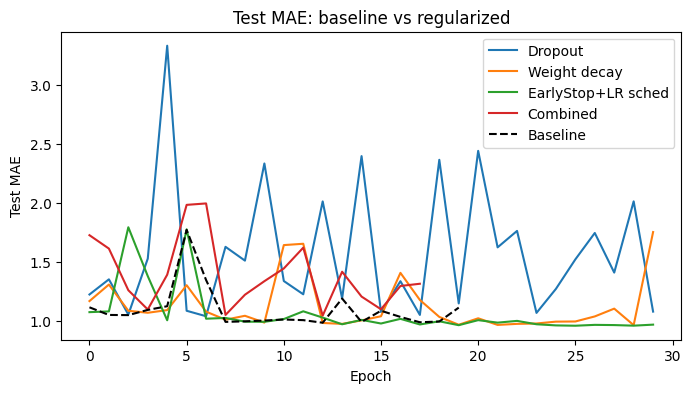

In [46]:
#comparing the curves
plt.figure(figsize=(8, 4))
for name, h in hists.items():
    plt.plot(h['test_mae'], label=name)
plt.plot(hist_base['test_mae'], label='Baseline', linestyle='--', color='k')
plt.xlabel('Epoch'); plt.ylabel('Test MAE'); plt.legend()
plt.title('Test MAE: baseline vs regularized')
plt.show()